## Practice: Basic Artificial Neural Networks
Credits: this notebook belongs to [Practical DL](https://docs.google.com/forms/d/e/1FAIpQLScvrVtuwrHSlxWqHnLt1V-_7h2eON_mlRR6MUb3xEe5x9LuoA/viewform?usp=sf_link) course by Yandex School of Data Analysis.

We will start working with neural networks on the practice session. Your homework will be to finish the implementation of the layers.

Our goal is simple, yet an actual implementation may take some time :). We are going to write an Artificial Neural Network (almost) from scratch. The software design was heavily inspired by [PyTorch](http://pytorch.org) which is the main framework of our course 

Speaking about the homework (once again, it will be really similar to this seminar), it requires sending **multiple** files, please do not forget to include all the files when sending to TA. The list of files:
- This notebook
- modules.ipynb with all blocks implemented (except maybe `Conv2d` and `MaxPool2d` layers implementation which are part of 'advanced' version of this homework)

In [146]:
%matplotlib inline
from time import time, sleep
import numpy as np
import matplotlib.pyplot as plt
from IPython import display

# Framework

Implement everything in `modules.ipynb`. Read all the comments thoughtfully to ease the pain. Please try not to change the prototypes.

Do not forget, that each module should return **AND** store `output` and `gradInput`.

The typical assumption is that `module.backward` is always executed after `module.forward`,
so `output` is stored, this would be useful for `SoftMax`. 

### Tech note
Prefer using `np.multiply`, `np.add`, `np.divide`, `np.subtract` instead of `*`,`+`,`/`,`-` for better memory handling.

Example: suppose you allocated a variable 

```
a = np.zeros(...)
```
So, instead of
```
a = b + c  # will be reallocated, GC needed to free
``` 
You can use: 
```
np.add(b,c,out = a) # puts result in `a`
```

In [147]:
#%pip install scikit-image

In [148]:
# (re-)load layers
%run modules.ipynb

<>:3: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\barto\AppData\Local\Temp\ipykernel_5832\2367876760.py:3: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  Implements linear transform of input y = \gamma * x + \beta


# Toy example

Use this example to debug your code, start with logistic regression and then test other layers. You do not need to change anything here. This code is provided for you to test the layers. Also it is easy to use this code in MNIST task.

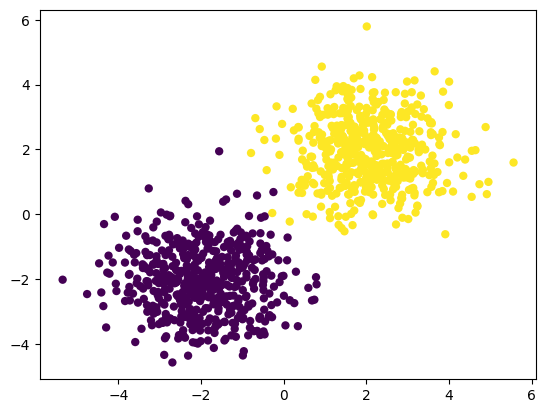

In [149]:
# Generate some data
N = 500

X1 = np.random.randn(N,2) + np.array([2,2])
X2 = np.random.randn(N,2) + np.array([-2,-2])

Y = np.concatenate([np.ones(N),np.zeros(N)])[:,None]
Y = np.hstack([Y, 1-Y])

X = np.vstack([X1,X2])
plt.scatter(X[:,0],X[:,1], c = Y[:,0], edgecolors= 'none')

Define a **logistic regression** for debugging. 

In [150]:
net = Sequential()
net.add(Linear(2, 2))
net.add(LogSoftMax())

criterion = ClassNLLCriterion()

print(net)

# Test something like that then 

# net = Sequential()
# net.add(Linear(2, 4))
# net.add(ReLU())
# net.add(Linear(4, 2))
# net.add(LogSoftMax())

Linear 2 -> 2
LogSoftMax



Start with batch_size = 1000 to make sure every step lowers the loss, then try stochastic version.

In [151]:
# Iptimizer params
optimizer_config = {'learning_rate' : 1e-1, 'momentum': 0.9}
optimizer_state = {}

# Looping params
n_epoch = 20
batch_size = 128

In [152]:
# batch generator
def get_batches(dataset, batch_size):
    X, Y = dataset
    n_samples = X.shape[0]
        
    # Shuffle at the start of epoch
    indices = np.arange(n_samples)
    np.random.shuffle(indices)
    
    for start in range(0, n_samples, batch_size):
        end = min(start + batch_size, n_samples)
        
        batch_idx = indices[start:end]
    
        yield X[batch_idx], Y[batch_idx]

### Train

Basic training loop. Examine it.

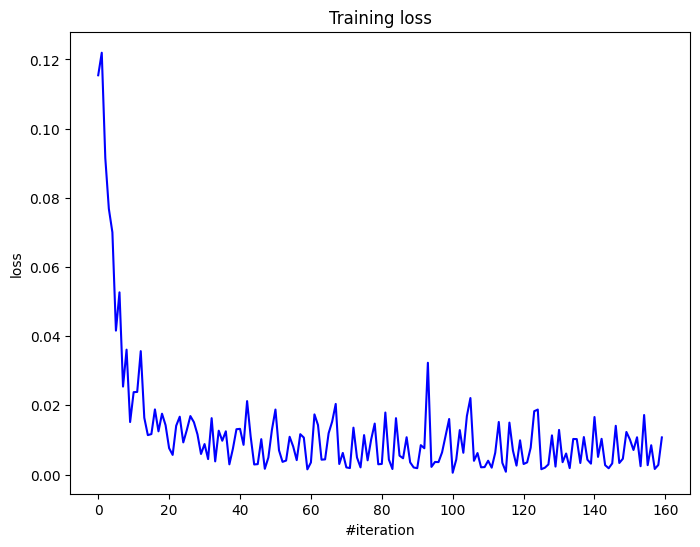

Current loss: 0.010724


In [153]:
loss_history = []

for i in range(n_epoch):
    for x_batch, y_batch in get_batches((X, Y), batch_size):
        
        net.zeroGradParameters()
        
        # Forward
        predictions = net.forward(x_batch)
        loss = criterion.forward(predictions, y_batch)
    
        # Backward
        dp = criterion.backward(predictions, y_batch)
        net.backward(x_batch, dp)
        
        # Update weights
        sgd_momentum(net.getParameters(), 
                     net.getGradParameters(), 
                     optimizer_config,
                     optimizer_state)      
        
        loss_history.append(loss)

    # Visualize
    display.clear_output(wait=True)
    plt.figure(figsize=(8, 6))
        
    plt.title("Training loss")
    plt.xlabel("#iteration")
    plt.ylabel("loss")
    plt.plot(loss_history, 'b')
    plt.show()
    
    print('Current loss: %f' % loss)    

# Digit classification 

We are using old good [MNIST](http://yann.lecun.com/exdb/mnist/) as our dataset. It can be downloaded with the following file.

In [154]:
#!wget https://raw.githubusercontent.com/girafe-ai/ml-course/23f_basic/homeworks/hw08_nn_from_scratch/mnist.py -nc

In [155]:
import mnist
X_train, y_train, X_val, y_val, X_test, y_test = mnist.load_dataset()

print(X_train.shape)
print(y_train.shape)
print(y_train[:10])
print(y_train.dtype)

(50000, 28, 28)
(50000,)
[5 0 4 1 9 2 1 3 1 4]
uint8


One-hot encode the labels first.

In [156]:
id = np.eye(10)
#X_train, y_train, X_val, y_val, X_test, y_test 
Y_train = id[y_train]
Y_val = id[y_val]
Y_test = id[y_test]

X_train_flat = X_train.reshape(X_train.shape[0], -1)
X_val_flat = X_val.reshape(X_val.shape[0], -1)
X_test_flat = X_test.reshape(X_test.shape[0], -1)

print(X_train_flat.shape, X_val_flat.shape, X_test_flat.shape )

(50000, 784) (10000, 784) (10000, 784)


- **Compare** `ReLU`, `ELU`, `LeakyReLU`, `SoftPlus` activation functions. 
You would better pick the best optimizer params for each of them, but it is overkill for now. Use an architecture of your choice for the comparison.
- **Try** inserting `BatchNormalization` (folowed by `ChannelwiseScaling`) between `Linear` module and activation functions.
- Plot the losses both from activation functions comparison and `BatchNormalization` comparison on one plot. Please find a scale (log?) when the lines are distinguishable, do not forget about naming the axes, the plot should be goodlooking.
- Plot the losses for two networks: one trained by momentum_sgd, another one trained by Adam. Which one performs better?
- Hint: good logloss for MNIST should be around 0.5. 

In [157]:
net = Sequential()
net.add(Linear(784, 64))
net.add(ReLU())
net.add(Linear(64, 10))
net.add(LogSoftMax())

criterion = ClassNLLCriterion()

print(net)

# Test something like that then 

# net = Sequential()
# net.add(Linear(2, 4))
# net.add(ReLU())
# net.add(Linear(4, 2))
# net.add(LogSoftMax())
predictions = net.forward(X_train_flat[:5])

print(predictions.shape)
print(np.exp(predictions).sum(axis=1))

Linear 784 -> 64
ReLU
Linear 64 -> 10
LogSoftMax

(5, 10)
[1. 1. 1. 1. 1.]


In [158]:
optimizer_config = {
    'learning_rate': 0.001,
    'beta1': 0.9,
    'beta2': 0.999,
    'epsilon': 1e-8
}

optimizer_state = {}

n_epoch = 5
batch_size = 128

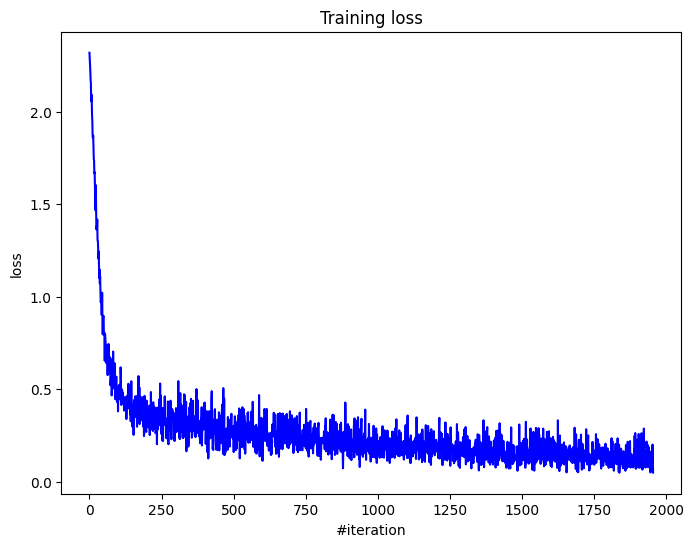

Current loss: 0.050406


In [159]:
loss_history = []

net.train()

for i in range(n_epoch):
    for x_batch, y_batch in get_batches((X_train_flat, Y_train), batch_size):
        
        net.zeroGradParameters()
        
        # Forward
        predictions = net.forward(x_batch)
        loss = criterion.forward(predictions, y_batch)
    
        # Backward
        dp = criterion.backward(predictions, y_batch)
        net.backward(x_batch, dp)
        
        # Update weights
        adam_optimizer(net.getParameters(), 
                     net.getGradParameters(), 
                     optimizer_config,
                     optimizer_state)      
        
        loss_history.append(loss)

    # Visualize
    display.clear_output(wait=True)
    plt.figure(figsize=(8, 6))
        
    plt.title("Training loss")
    plt.xlabel("#iteration")
    plt.ylabel("loss")
    plt.plot(loss_history, 'b')
    plt.show()
    
    print('Current loss: %f' % loss)    

In [160]:
net.evaluate()

val_predictions = net.forward(X_val_flat)
val_loss = criterion.forward(val_predictions, Y_val)
predicted_classes = np.argmax(val_predictions, axis=1)


print(val_loss)
print(val_predictions.shape)
print(predicted_classes.shape)

accuracy = np.mean(predicted_classes == y_val)
print(f"accuracy {accuracy:.2%}")


0.13585633070082986
(10000, 10)
(10000,)
accuracy 96.11%


In [161]:
def build_net(activation, use_bn=False, dropout_p=0):
   
   
   net = Sequential()
   net.add(Linear(784, 64))
   if use_bn:
       net.add(BatchNormalization(alpha=0.9))
       net.add(ChannelwiseScaling(64))
       
   net.add(activation)

   if dropout_p > 0:
       net.add(Dropout(p=dropout_p))
   net.add(Linear(64, 10))
   net.add(LogSoftMax())
   
   return net

def train_net(net, n_epoch=5, batch_size=128, optimizer="adam",lr_decay=1.0):
    
    if optimizer == "adam":
  
        optimizer_config = {
        'learning_rate': 0.001,
        'beta1': 0.9,
        'beta2': 0.999,
        'epsilon': 1e-8
    }
    
    
    elif optimizer == "sgd":
        optimizer_config = {
        'learning_rate': 0.1,
        'momentum': 0.9
    }
    
    optimizer_state = {}
    loss_history = []
    criterion = ClassNLLCriterion()

    net.train()

    for i in range(n_epoch):
        for x_batch, y_batch in get_batches((X_train_flat, Y_train), batch_size):
            net.zeroGradParameters()
            prediction = net.forward(x_batch)
            loss = criterion.forward(prediction, y_batch)

            dp = criterion.backward(prediction, y_batch)
            net.backward(x_batch, dp)

            if optimizer == "adam":
                adam_optimizer(net.getParameters(), net.getGradParameters(), optimizer_config, optimizer_state)
            elif optimizer == "sgd":
                    sgd_momentum(net.getParameters(), 
                    net.getGradParameters(), 
                    optimizer_config,
                    optimizer_state)   
            
            loss_history.append(loss)
        optimizer_config['learning_rate'] *= lr_decay
    return loss_history

  


In [162]:
np.random.seed(42)
net_relu = build_net(ReLU())
history_relu = train_net(net_relu)
print(history_relu[0], history_relu[-1])

np.random.seed(42)
net_elu = build_net(ELU())
history_elu = train_net(net_elu)
print(history_elu[0], history_elu[-1])

np.random.seed(42)
net_leakyrelu = build_net(LeakyReLU())
history_leakyrelu = train_net(net_leakyrelu)
print(history_leakyrelu[0], history_leakyrelu[-1])

np.random.seed(42)
net_softplus = build_net(SoftPlus())
history_softplus = train_net(net_softplus)
print(history_softplus[0], history_softplus[-1])

2.319883825555704 0.1462849646195512
2.3187542599682205 0.17576860172658942
2.3197375940799683 0.1612238150142114
2.5621787151417617 0.20440951206588015


In [163]:
def evaluate_net(net):
    net.evaluate()
    criterion = ClassNLLCriterion()
    val_predictions = net.forward(X_val_flat)
    val_loss = criterion.forward(val_predictions, Y_val)
    predicted_classes = np.argmax(val_predictions, axis=1)
    accuracy = np.mean(predicted_classes == y_val)

    return val_loss, accuracy

In [164]:
relu_loss, relu_accuracy = evaluate_net(net_relu)
elu_loss, elu_accuracy = evaluate_net(net_elu)
leakyrelu_loss, leakyrelu_accuracy = evaluate_net(net_leakyrelu)
softplus_loss, softplus_accuracy = evaluate_net(net_softplus)

print(f"ReLU: loss = {relu_loss:.4f}, accuracy = {relu_accuracy:.2%}")
print(f"ELU:  loss = {elu_loss:.4f}, accuracy = {elu_accuracy:.2%}")
print(f"LeakyReLU: loss = {leakyrelu_loss:.4f}, accuracy = {leakyrelu_accuracy:.2%}")
print(f"SoftPlus:  loss = {softplus_loss:.4f}, accuracy = {softplus_accuracy:.2%}")

ReLU: loss = 0.1379, accuracy = 96.04%
ELU:  loss = 0.1411, accuracy = 96.08%
LeakyReLU: loss = 0.1401, accuracy = 96.00%
SoftPlus:  loss = 0.1638, accuracy = 95.48%


In [165]:
net_bn = build_net(ReLU(), use_bn=True)
print(net_bn)
np.random.seed(42)
net_bn = build_net(ReLU(), use_bn=True)
history_bn = train_net(net_bn)

bn_loss, bn_accuracy = evaluate_net(net_bn)
print(f"ReLU + BN: loss = {bn_loss:.4f}, accuracy = {bn_accuracy:.2%}")


Linear 784 -> 64
BatchNormalization
ChannelwiseScaling
ReLU
Linear 64 -> 10
LogSoftMax



ReLU + BN: loss = 0.1466, accuracy = 96.00%


In [166]:
def smooth_history(history, block_size=25):
    n_blocks = len(history) // block_size
    n_values = n_blocks * block_size
    trimmed = np.asarray(history[:n_values])
    blocks = trimmed.reshape(-1, block_size)
    mean_loss = blocks.mean(axis=1)
    steps = np.arange(block_size, n_values + 1, block_size)
    return steps, mean_loss

In [167]:
histories = [
    ("ReLU", history_relu),
    ("ELU", history_elu),
    ("LeakyReLU", history_leakyrelu),
    ("SoftPlus", history_softplus),
    ("ReLU + BN (alpha=0.9)", history_bn)    
]


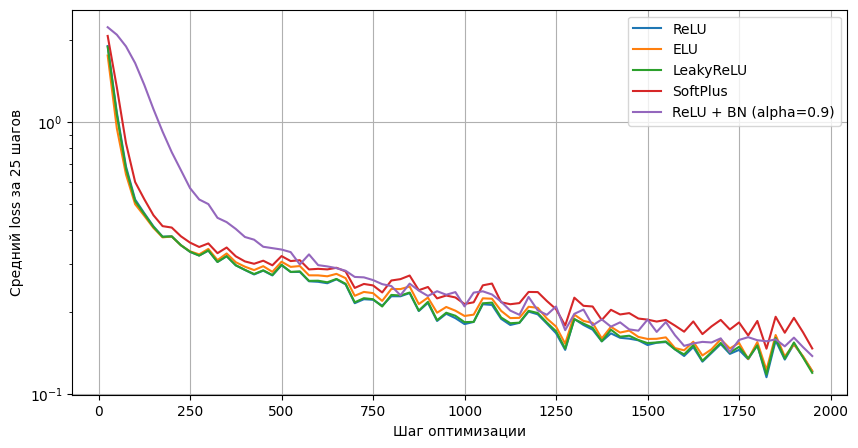

In [168]:
plt.figure(figsize=(10, 5))

for label, history in histories:
    steps, mean_loss = smooth_history(history)
    plt.plot(steps, mean_loss, label=label)

plt.xlabel("Шаг оптимизации")
plt.ylabel("Средний loss за 25 шагов")
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()

Write your personal opinion on the activation functions, think about computation times too. Does `BatchNormalization` help?

ReLU, ELU и LeakyReLU показали близкие результаты. SoftPlus показал худший результат по обеим метрикам на валидации — loss 0.1638 и accuracy 95.48%. У ReLU с BatchNorm тренировочный loss в начале снижался медленнее, а к концу приблизился к loss обычного ReLU. В этом запуске BatchNorm не улучшил качество на валидации: loss вырос с 0.1379 до 0.1466, а accuracy почти не изменилась (96.04% → 96.00%).

In [169]:

np.random.seed(42)
net_sgd = build_net(ReLU())
history_sgd = train_net(net_sgd, optimizer="sgd")
sgd_loss, sgd_accuracy = evaluate_net(net_sgd)
print(f"SGD + ReLU : loss = {sgd_loss:.4f}, accuracy = {sgd_accuracy:.2%}")


SGD + ReLU : loss = 0.1052, accuracy = 96.87%


In [170]:
histories = [
    ("Adam", history_relu),
    ("SGD + momentum", history_sgd)  
]


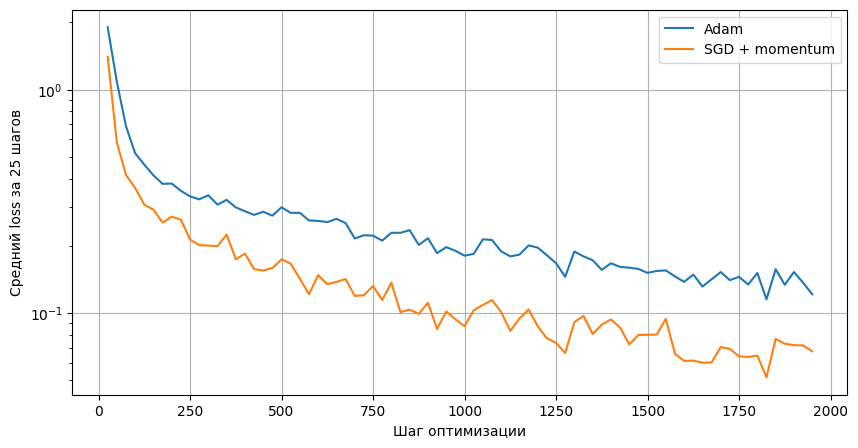

In [171]:
plt.figure(figsize=(10, 5))

for label, history in histories:
    steps, mean_loss = smooth_history(history)
    plt.plot(steps, mean_loss, label=label)

plt.xlabel("Шаг оптимизации")
plt.ylabel("Средний loss за 25 шагов")
plt.legend()
plt.grid()
plt.yscale("log")
plt.show()

При одинаковом числе шагов обучения SGD с momentum показал более низкий тренировочный loss, чем Adam. Сравнение относится к выбранным настройкам оптимизаторов.
Результат на валидации: SGD с momentum — loss 0.1052 и accuracy 96.87%, Adam — 0.1379 и 96.04%. При выбранных настройках SGD оказался лучше по обеим метрикам.

**Finally**, use all your knowledge to build a super cool model on this dataset. Use **dropout** to prevent overfitting, play with **learning rate decay**. You can use **data augmentation** such as rotations, translations to boost your score. Use your knowledge and imagination to train a model. Don't forget to call `training()` and `evaluate()` methods to set desired behaviour of `BatchNormalization` and `Dropout` layers.

In [172]:

np.random.seed(42)
net_dropout = build_net(ReLU(), dropout_p=0.2)
history_dropout = train_net(net_dropout, optimizer="sgd")
dropout_loss, dropout_accuracy = evaluate_net(net_dropout)
print(f"Dropout+ ReLU : loss = {dropout_loss:.4f}, accuracy = {dropout_accuracy:.2%}")


Dropout+ ReLU : loss = 0.1053, accuracy = 97.14%


In [173]:

np.random.seed(42)
net_decay = build_net(ReLU(), dropout_p=0.2)
history_decay = train_net(net_decay, optimizer="sgd",lr_decay=0.9)
decay_loss, decay_accuracy = evaluate_net(net_decay)
print(f"Dropout+ ReLU : loss = {decay_loss:.4f}, accuracy = {decay_accuracy:.2%}")


Dropout+ ReLU : loss = 0.1016, accuracy = 97.11%


Print here your accuracy on test set. It should be around 90%.

In [174]:
net_dropout.evaluate()

test_predictions = net_dropout.forward(X_test_flat)
test_loss = criterion.forward(test_predictions, Y_test)
predicted_classes = np.argmax(test_predictions, axis=1)

accuracy = np.mean(predicted_classes == y_test)
print(f"loss: {test_loss:.4f}, accuracy: {accuracy:.2%}")

loss: 0.1014, accuracy: 96.96%


Dropout поднял validation accuracy с 96.87% до 97.14%. Со снижением learning rate validation loss стал ниже (0.1016 против 0.1053), а accuracy оказалась чуть ниже (97.11% против 97.14%)

### Comparing with PyTorch implementation
The last (and maybe the easiest step after compared to the previous tasks: build a network with the same architecture as above now with PyTorch.

You can refer to the `week0_09` or `Lab3_part2` notebooks for hints.

__Good Luck!__

In [175]:
import torch
from torch import nn

model = nn.Sequential(
    nn.Linear(784, 64),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(64, 10),
    nn.LogSoftmax(dim=1)
)

print(model)

x_batch = torch.tensor(
    X_train_flat[:5],
    dtype=torch.float32
)

predictions = model(x_batch)
print(x_batch.shape)
print(predictions.shape)
print(predictions.exp().sum(dim=1))

targets = torch.tensor(y_train[:5], dtype=torch.long)

criterion_torch = nn.NLLLoss()
loss_torch = criterion_torch(predictions, targets)

print(targets)
print(loss_torch)
print(loss_torch.shape)

Sequential(
  (0): Linear(in_features=784, out_features=64, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.2, inplace=False)
  (3): Linear(in_features=64, out_features=10, bias=True)
  (4): LogSoftmax(dim=1)
)
torch.Size([5, 784])
torch.Size([5, 10])
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)
tensor([5, 0, 4, 1, 9])
tensor(2.3692, grad_fn=<NllLossBackward0>)
torch.Size([])


In [176]:
optimizer_torch = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9
)



In [177]:
optimizer_torch.zero_grad()
predictions = model(x_batch)
loss_torch = criterion_torch(predictions, targets)
loss_torch.backward()
optimizer_torch.step()
print(loss_torch.item())


2.3319618701934814


In [178]:
from torch.utils.data import TensorDataset, DataLoader

X_train_t = torch.tensor(X_train_flat, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.long)
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

torch.manual_seed(42)

model = nn.Sequential(
    nn.Linear(784, 64),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(64, 10),
    nn.LogSoftmax(dim=1)
)

optimizer_torch = torch.optim.SGD(
    model.parameters(),
    lr=0.1,
    momentum=0.9
)

criterion_torch = nn.NLLLoss()

n_epoch = 5
history_torch = []

model.train()

for epoch in range(n_epoch):
    for x_batch, targets in train_loader:
        optimizer_torch.zero_grad()
        predictions = model(x_batch)
        loss_torch = criterion_torch(predictions, targets)
        loss_torch.backward()
        optimizer_torch.step() 

        history_torch.append(loss_torch.item())
    print(f"Epoch {epoch} loss = {loss_torch.item():.4f}")

Epoch 0 loss = 0.2435
Epoch 1 loss = 0.1567
Epoch 2 loss = 0.1243
Epoch 3 loss = 0.0882
Epoch 4 loss = 0.1101


In [179]:
X_val_t = torch.tensor(X_val_flat, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.long)

model.eval()

with torch.no_grad():
    val_predictions_torch = model(X_val_t)
    val_loss_torch = criterion_torch(val_predictions_torch, y_val_t)

print(val_loss_torch.item())

predicted_classes_torch = val_predictions_torch.argmax(dim=1)

correct = predicted_classes_torch == y_val_t

accuracy = correct.float().mean().item()
print(f"accuracy {accuracy:.2%}")


0.10443990677595139
accuracy 96.90%


In [180]:
X_test_t = torch.tensor(X_test_flat, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.long)

model.eval()

with torch.no_grad():
    test_predictions_torch = model(X_test_t)
    test_loss_torch = criterion_torch(test_predictions_torch, y_test_t)

print(test_loss_torch.item())

predicted_classes_torch = test_predictions_torch.argmax(dim=1)

correct = predicted_classes_torch == y_test_t

accuracy = correct.float().mean().item()
print(f"accuracy {accuracy:.2%}")


0.09840499609708786
accuracy 97.07%


In [181]:
from time import perf_counter

In [182]:
np.random.seed(42)
net_numpy_timing = build_net(ReLU(), dropout_p=0.2)

start = perf_counter()

train_net(net_numpy_timing, optimizer="sgd")

elapsed = perf_counter() - start

numpy_time = elapsed

print(numpy_time)

2.6075540999881923


In [183]:
torch.manual_seed(42)

model_timing = nn.Sequential(
    nn.Linear(784, 64),
    nn.ReLU(),
    nn.Dropout(p=0.2),
    nn.Linear(64, 10),
    nn.LogSoftmax(dim=1)
)

optimizer_timing = torch.optim.SGD(
    model_timing.parameters(),
    lr=0.1,
    momentum=0.9
)

model_timing.train()
history_timing = []

start = perf_counter()

for epoch in range(5):
    for x_batch, targets in train_loader:
        optimizer_timing.zero_grad()
        predictions = model_timing(x_batch)
        loss_torch = criterion_torch(predictions, targets)
        loss_torch.backward()
        optimizer_timing.step()
        history_timing.append(loss_torch.item())

torch_time = perf_counter() - start
print(torch_time)


2.366726499982178


На тесте результаты близкие: NumPy — 96.96%, PyTorch — 97.07%. Пять эпох заняли 2.61 с и 2.37 с в одном запуске. Для меня главное преимущество PyTorch в том, что градиенты считаются автоматически и кода получается меньше.